# Predicting Lithium-Ion Battery Cycle Life from the First 100 Cycles

**Author:** Huzaifa Ahmad

**Goal.** Predict how many charge–discharge cycles a lithium-ion cell will last, using only its first 100 cycles.

**Data credit.** 124 commercial LFP/graphite cells (41 training, 43 primary-test, 40 secondary-test) from the dataset of Severson et al. (2019). This notebook uses the processed capacity-vs-voltage arrays and cycle lives published by Attia et al. (2021) in [petermattia/revisit-severson-et-al](https://github.com/petermattia/revisit-severson-et-al) (MIT licence). The original dataset is hosted at [data.matr.io](https://data.matr.io/1/projects/5c48dd2bc625d700019f3204); check its licence terms before reusing it.

**Method in one line.** ΔQ(V) = Q(V) at cycle 100 − Q(V) at cycle 10 → feature = log10 of its variance → regularised linear model (elastic net), compared with two baselines, a five-feature model and a random forest.

**AI assistance.** The code and the text in this notebook were drafted with the help of an AI assistant (Claude). I ran the notebook in Google Colab and checked that its results reproduce the reference values for the paper's variance model (RMSE 103.6 / 138.4 / 196.0 cycles).

*How to run:* open the notebook in Google Colab and choose **Runtime → Run all**. It needs an internet connection to download the data.

## 1. Setup
Loads the libraries, fixes the random seed so results repeat exactly, and creates a `results/` folder for figures and tables.

In [1]:
import re, glob, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis, pearsonr
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import ElasticNetCV
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 0                                   # fixed seed -> repeatable results
np.random.seed(SEED)
OUT_DIR = Path('results'); OUT_DIR.mkdir(exist_ok=True)    # figures and tables are saved here
VDLIN = np.linspace(3.6, 2.0, 1000)        # the 1000 voltage points (V), 3.6 V down to 2.0 V
COLORS = {'train': 'tab:blue', 'test1': 'tab:red', 'test2': 'tab:orange'}

## 2. Load the data
Downloads the public data repository and reads each cell's capacity-vs-voltage array (1,000 voltages × 99 cycles, covering cycles 2–100) and its cycle life.

**Finding:** there are 124 cells in three groups: 41 training, 43 primary test and 40 secondary test. The secondary-test cells live longer (median 964 cycles vs 527 for training), so they make the harder and more honest test.

In [2]:
if not os.path.exists('revisit-severson-et-al'):
    !git clone --depth 1 https://github.com/petermattia/revisit-severson-et-al.git
DATA_DIR = Path('revisit-severson-et-al/data')

def load_split(split):
    files = glob.glob(f'{DATA_DIR}/{split}/cell*.csv')
    files.sort(key=lambda p: int(re.search(r'cell(\d+)\.csv', p).group(1)))   # cell2 before cell10
    Q = np.stack([pd.read_csv(f, header=None).to_numpy() for f in files])      # (cells, 1000 voltages, 99 cycles)
    life = pd.read_csv(f'{DATA_DIR}/cycle_lives/{split}_cycle_lives.csv', header=None)[0].to_numpy(dtype=float)
    assert len(Q) == len(life)
    return Q, life

SPLITS = ['train', 'test1', 'test2']       # test1 = "primary test", test2 = "secondary test"
Q, life = {}, {}
for s in SPLITS:
    Q[s], life[s] = load_split(s)
    print(f'{s:6s} cells={len(life[s]):3d}  array={Q[s].shape}  life min/median/max='
          f'{life[s].min():.0f}/{np.median(life[s]):.0f}/{life[s].max():.0f}  NaNs={np.isnan(Q[s]).sum()}')

y = {s: np.log10(life[s]) for s in SPLITS}                  # we predict log10(cycle life)
OUTLIER = 21                                                # test1 cell with life 148
assert life['test1'][OUTLIER] == 148
keep = {s: np.ones(len(life[s]), bool) for s in SPLITS}     # True = cell counts in headline metrics
keep['test1'][OUTLIER] = False

Cloning into 'revisit-severson-et-al'...
remote: Enumerating objects: 174, done.
remote: Counting objects: 100% (174/174), done.
remote: Compressing objects: 100% (172/172), done.
remote: Total 174 (delta 13), reused 152 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (174/174), 25.49 MiB | 5.62 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Updating files: 100% (164/164), done.
train  cells= 41  array=(41, 1000, 99)  life min/median/max=300/527/2160  NaNs=0
test1  cells= 43  array=(43, 1000, 99)  life min/median/max=148/561/2237  NaNs=0
test2  cells= 40  array=(40, 1000, 99)  life min/median/max=541/964/1935  NaNs=0


## 3. Helper functions
Defines the functions used below: pick a cycle, build ΔQ(V), compute features, measure error (RMSE and % error) and create the model. Nothing is calculated yet.

In [3]:
def Q_at(Qs, cycle):                       # arrays start at cycle 2, so cycle c is column c-2
    return Qs[:, :, cycle - 2]

def delta_q(Qs, late=100, early=10):       # dQ(V) = Q_late(V) - Q_early(V) -> shape (cells, 1000)
    return Q_at(Qs, late) - Q_at(Qs, early)

def feat_variance(dq):                     # the paper's one feature: log10 of the variance of dQ(V)
    return np.log10(np.var(dq, axis=1)).reshape(-1, 1)

def feat_stats(dq):                        # 5 summary numbers of the dQ curve (log10 of absolute value)
    eps = 1e-12                            # avoids log10(0)
    return np.column_stack([
        np.log10(np.abs(dq.min(axis=1)) + eps),
        np.log10(np.abs(dq.mean(axis=1)) + eps),
        np.log10(np.var(dq, axis=1)),
        np.log10(np.abs(skew(dq, axis=1)) + eps),
        np.log10(np.abs(kurtosis(dq, axis=1)) + eps)])

def feat_capacity(Qs):                     # naive baseline: capacity lost between cycle 10 and 100
    cap = lambda c: Q_at(Qs, c)[:, -1]     # last voltage row (2.0 V) = total discharge capacity
    return (cap(10) - cap(100)).reshape(-1, 1)

def rmse_cycles(y_true, y_pred):           # typical error in CYCLES (undo the log10 first)
    return float(np.sqrt(mean_squared_error(10**y_true, 10**y_pred)))

def pct_error(y_true, y_pred):             # average error as a % of the true life
    return float(np.mean(np.abs(10**y_pred - 10**y_true) / 10**y_true) * 100)

def make_enet():                           # scale features -> linear model with automatic regularisation
    return make_pipeline(StandardScaler(),
                         ElasticNetCV(l1_ratio=[.1, .5, .7, .9, .95, .99, 1], cv=5,
                                      max_iter=100_000, random_state=SEED))

## 4. Data-quality check
Looks for impossible capacity values (above 1.3 Ah or clearly negative; these cells hold about 1.1 Ah) before any modelling.

**Finding:** seven cells (3 training, 4 primary-test) have corrupt curves at cycles 12, 13, 73 or 74. None of the cycles the model uses (10, 20, …, 100) is affected, so the results are unaffected.

In [4]:
for s in SPLITS:
    bad = np.argwhere((Q[s] > 1.3) | (Q[s] < -0.05))        # rows of (cell, voltage_row, cycle_column)
    pairs = sorted({(int(c), int(k) + 2) for c, _, k in bad})
    print(f'{s:6s} corrupt (cell, cycle): {pairs}')
for s in SPLITS:                                             # every cycle our features touch must be clean
    for c in range(10, 101, 10):
        assert -0.05 < Q_at(Q[s], c).min() and Q_at(Q[s], c).max() < 1.3, f'corrupt data: {s}, cycle {c}'
print('cycles 10, 20, ..., 100 are clean in all cells')

train  corrupt (cell, cycle): [(1, 12), (8, 13), (15, 73)]
test1  corrupt (cell, cycle): [(0, 12), (2, 12), (8, 13), (38, 74)]
test2  corrupt (cell, cycle): []
cycles 10, 20, ..., 100 are clean in all cells


## 5. Look at the data
Draws six plots: cycle-life histogram, capacity vs cycle, Q(V) curves, ΔQ(V) curves, correlation of ΔQ with life at each voltage, and the key feature against life.

**Finding:** capacity is almost flat for most cells over 100 cycles, yet the variance of ΔQ(V) is strongly linked to cycle life (Pearson r = −0.90, −0.93 and −0.81 for training, primary and secondary test). The link is strongest between about 2.0 V and 3.2 V (peak r = 0.82 at 2.95 V).

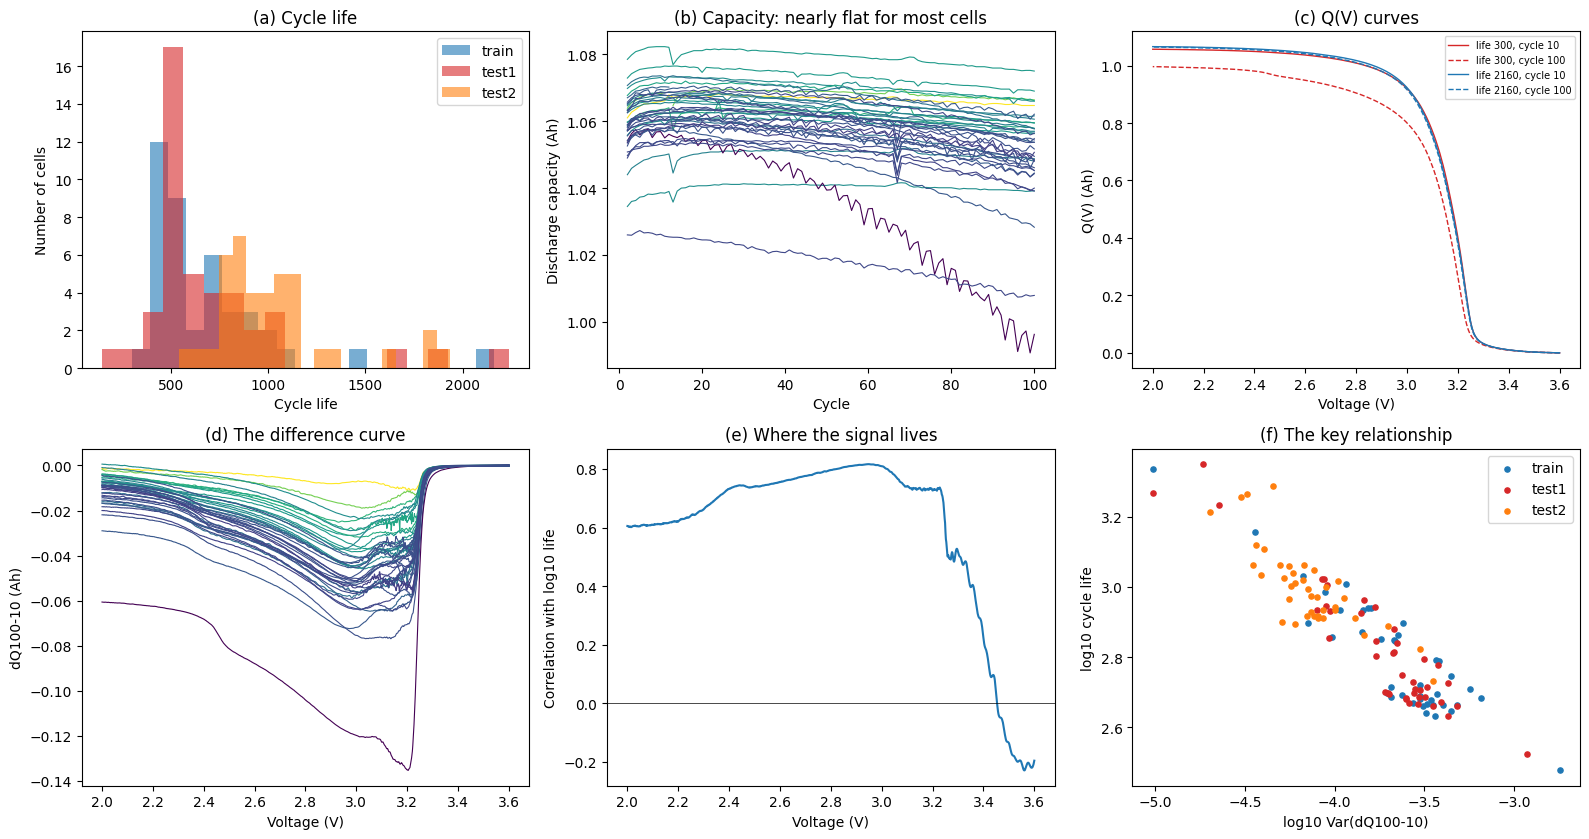

train: Pearson r = -0.904
test1: Pearson r = -0.932
test2: Pearson r = -0.805


In [5]:
cmap, norm = plt.cm.viridis, plt.Normalize(y['train'].min(), y['train'].max())   # colour = log10 life
dq_train = delta_q(Q['train'])
fig, ax = plt.subplots(2, 3, figsize=(16, 8.5))

for s in SPLITS:                                                                   # (a)
    ax[0, 0].hist(life[s], bins=20, alpha=.6, color=COLORS[s], label=s)
ax[0, 0].set(xlabel='Cycle life', ylabel='Number of cells', title='(a) Cycle life'); ax[0, 0].legend()

cap = Q['train'][:, -1, :].copy(); cap[(cap > 1.3) | (cap < 0.5)] = np.nan          # (b) corrupt points hidden
for i in range(len(cap)):
    ax[0, 1].plot(range(2, 101), cap[i], color=cmap(norm(y['train'][i])), lw=.8)
ax[0, 1].set(xlabel='Cycle', ylabel='Discharge capacity (Ah)', title='(b) Capacity: nearly flat for most cells')

for i, col in [(np.argmin(life['train']), 'tab:red'), (np.argmax(life['train']), 'tab:blue')]:   # (c)
    for c, ls in [(10, '-'), (100, '--')]:
        ax[0, 2].plot(VDLIN, Q_at(Q['train'], c)[i], color=col, ls=ls, lw=1,
                      label=f'life {life["train"][i]:.0f}, cycle {c}')
ax[0, 2].set(xlabel='Voltage (V)', ylabel='Q(V) (Ah)', title='(c) Q(V) curves'); ax[0, 2].legend(fontsize=7)

for i in range(len(dq_train)):                                                     # (d)
    ax[1, 0].plot(VDLIN, dq_train[i], color=cmap(norm(y['train'][i])), lw=.8)
ax[1, 0].set(xlabel='Voltage (V)', ylabel='dQ100-10 (Ah)', title='(d) The difference curve')

corr_v = np.array([np.corrcoef(dq_train[:, k], y['train'])[0, 1] for k in range(1000)])   # (e)
ax[1, 1].plot(VDLIN, corr_v); ax[1, 1].axhline(0, color='k', lw=.5)
ax[1, 1].set(xlabel='Voltage (V)', ylabel='Correlation with log10 life', title='(e) Where the signal lives')

for s in SPLITS:                                                                   # (f)
    f = feat_variance(delta_q(Q[s]))[:, 0]
    ax[1, 2].scatter(f[keep[s]], y[s][keep[s]], s=14, color=COLORS[s], label=s)
ax[1, 2].set(xlabel='log10 Var(dQ100-10)', ylabel='log10 cycle life', title='(f) The key relationship'); ax[1, 2].legend()

plt.tight_layout(); plt.savefig(OUT_DIR / 'eda.png', dpi=130); plt.show()
for s in SPLITS:
    f = feat_variance(delta_q(Q[s]))[:, 0]
    print(f'{s}: Pearson r = {pearsonr(f[keep[s]], y[s][keep[s]])[0]:.3f}')

## 6. Compare five models
Trains five models on the training cells only and scores each on all three groups, as RMSE in cycles and as a percentage of the true life.

**Finding:** the one-feature variance model cuts the error to roughly a third of the predict-the-average baseline on the training and primary-test cells and to under 40% on the secondary test (RMSE 103.6 / 138.4 / 196.0 vs 327.2 / 398.8 / 510.6 cycles). Five features (204.4) and a random forest (228.0) do not do better on the secondary test.

In [6]:
preds, rows = {}, []
def run(name, make_X, model):
    model.fit(make_X(Q['train']), y['train'])                  # learn from the TRAIN cells only
    row, preds[name] = {'model': name}, {}
    for s in SPLITS:
        p = model.predict(make_X(Q[s])); preds[name][s] = p
        m = keep[s]
        row[f'RMSE {s}'] = rmse_cycles(y[s][m], p[m])
        row[f'%err {s}'] = pct_error(y[s][m], p[m])
    row['RMSE test1 incl. outlier'] = rmse_cycles(y['test1'], preds[name]['test1'])
    rows.append(row)

dq100 = lambda Qs: delta_q(Qs)                                 # dQ between cycle 100 and cycle 10
run('Dummy (train mean)',     lambda Qs: feat_variance(dq100(Qs)), DummyRegressor())
run('Capacity fade only',     feat_capacity,                        make_enet())
run('Variance (1 feature)',   lambda Qs: feat_variance(dq100(Qs)),  make_enet())
run('dQ stats (5 features)',  lambda Qs: feat_stats(dq100(Qs)),     make_enet())
run('Random forest (5 feat)', lambda Qs: feat_stats(dq100(Qs)),     RandomForestRegressor(n_estimators=300, random_state=SEED))

results = pd.DataFrame(rows).set_index('model').round(1)
results.to_csv(OUT_DIR / 'model_comparison.csv')
results

,RMSE train,%err train,RMSE test1,%err test1,RMSE test2,%err test2,RMSE test1 incl. outlier
model,,,,,,,
Dummy (train mean),327.2,29.6,398.8,28.2,510.6,36.1,400.7
Capacity fade only,290.9,22.9,357.8,23.3,450.7,29.3,353.7
Variance (1 feature),103.6,14.1,138.4,13.2,196.0,11.4,138.0
dQ stats (5 features),99.9,13.2,127.5,13.3,204.4,11.5,132.1
Random forest (5 feat),79.0,6.0,165.8,13.3,228.0,12.9,167.1


## 7. Predicted versus observed
Plots the variance model's predictions against the true cycle lives; the dashed line is perfect prediction.

**Finding:** predictions follow the diagonal in all three groups. The largest errors are on the few very long-lived cells.

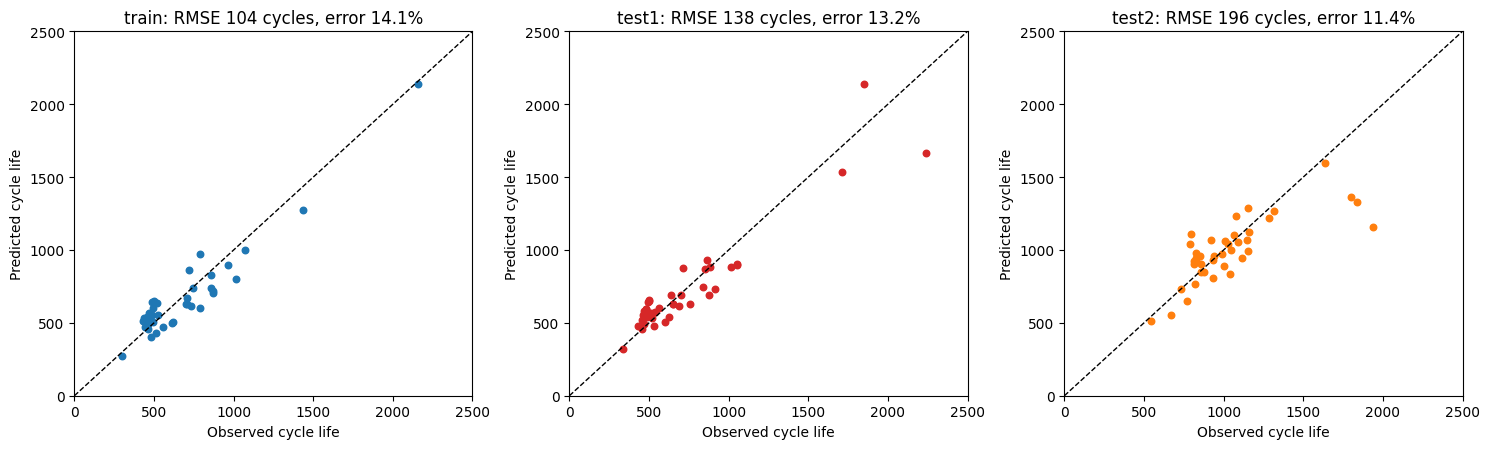

In [7]:
name = 'Variance (1 feature)'
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for a, s in zip(ax, SPLITS):
    m = keep[s]
    a.scatter(life[s][m], 10**preds[name][s][m], s=22, color=COLORS[s])
    a.plot([0, 2500], [0, 2500], 'k--', lw=1)                  # perfect prediction
    a.set(xlim=(0, 2500), ylim=(0, 2500), xlabel='Observed cycle life', ylabel='Predicted cycle life',
          title=f"{s}: RMSE {results.loc[name, f'RMSE {s}']:.0f} cycles, error {results.loc[name, f'%err {s}']:.1f}%")
plt.tight_layout(); plt.savefig(OUT_DIR / 'pred_vs_obs.png', dpi=130); plt.show()

## 8. Extension: how early is early enough?
Repeats the variance model using only cycles 10 to N, for N from 20 to 100.

**Finding:** at N = 20 the model is no better than the baseline. By N = 40 the secondary-test RMSE is 235.7 (baseline 510.6), and the full 100 cycles give 196.0. The curve is noisy because only 41 cells train the model.

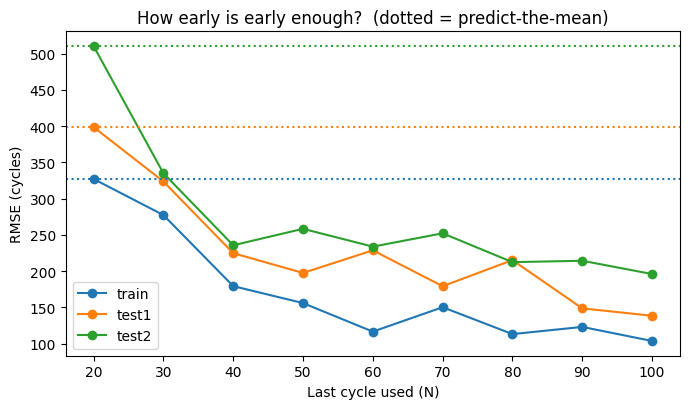

,train,test1,test2
N (last cycle used),,,
20,327.2,398.8,510.6
30,277.4,323.7,335.1
40,179.3,224.8,235.7
50,155.9,197.5,258.4
60,116.5,228.7,233.8
70,150.2,179.2,252.2
80,113.1,215.2,212.4
90,123.0,148.6,214.3
100,103.6,138.4,196.0


In [8]:
def fit_score(make_X, model):
    model.fit(make_X(Q['train']), y['train'])
    return {s: rmse_cycles(y[s][keep[s]], model.predict(make_X(Q[s]))[keep[s]]) for s in SPLITS}

windows = [20, 30, 40, 50, 60, 70, 80, 90, 100]               # last cycle used; reference cycle stays at 10
ablation = pd.DataFrame({N: fit_score(lambda Qs, N=N: feat_variance(delta_q(Qs, late=N)), make_enet())
                         for N in windows}).T.round(1)
ablation.index.name = 'N (last cycle used)'
ablation.to_csv(OUT_DIR / 'ablation_window.csv')

ax = ablation.plot(marker='o', figsize=(7, 4.2))
for s, line in zip(SPLITS, ax.get_lines()):                    # dotted = "predict the mean" baseline
    ax.axhline(results.loc['Dummy (train mean)', f'RMSE {s}'], ls=':', color=line.get_color())
ax.set(xlabel='Last cycle used (N)', ylabel='RMSE (cycles)', title='How early is early enough?  (dotted = predict-the-mean)')
plt.tight_layout(); plt.savefig(OUT_DIR / 'ablation_window.png', dpi=130); plt.show()
ablation

## 9. Save the results
Saves every cell's prediction to a CSV file and packs the `results/` folder into `results.zip`. The automatic download works only inside Google Colab.

In [9]:
pred_rows = [{'split': s, 'cell': i, 'observed_life': life[s][i],
              'predicted_life': 10**preds['Variance (1 feature)'][s][i], 'in_headline_metrics': bool(keep[s][i])}
             for s in SPLITS for i in range(len(life[s]))]
pd.DataFrame(pred_rows).round(1).to_csv(OUT_DIR / 'predictions.csv', index=False)

!zip -qr results.zip results
from google.colab import files
files.download('results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusions and limitations

**Conclusions**
- One feature from the first 100 cycles, the variance of ΔQ(V), predicts cycle life far better than capacity fade does (secondary-test RMSE 196.0 vs 450.7 cycles).
- More features or a random forest did not improve the secondary-test result: with only 41 training cells, the simple model generalises best.
- The secondary test is the honest estimate: the error grows from 138.4 to 196.0 cycles on cells from a later batch with longer lives.
- Predictions are already clearly better than the baseline by about cycle 40, but the trend is noisy.

**Limitations**
- One cell type (LFP/graphite), one dataset, 124 cells from one lab. Nothing here shows whether the method works for other chemistries.
- Training and primary-test cells come from the same batches, so the primary-test numbers are optimistic.
- Only ΔQ(V) features are used. The original paper's best models use more measurements and report lower error.
- Seven cells have corrupt curves at some cycles (not used by the model); they were not traced back to the raw data.
- The primary-test results leave out one cell (life 148 cycles), following the paper; including it changes the variance model's RMSE only from 138.4 to 138.0.
- The data arrays were produced by the original authors; this notebook did not re-extract them from the raw files.

## References
1. Severson, K. A., Attia, P. M., et al. Data-driven prediction of battery cycle life before capacity degradation. *Nature Energy* 4, 383–391 (2019). https://doi.org/10.1038/s41560-019-0356-8
2. Attia, P. M., et al. Statistical learning for accurate and interpretable battery lifetime prediction. *Journal of The Electrochemical Society* (2021). https://doi.org/10.1149/1945-7111/ac2704
3. Processed arrays and cycle lives: https://github.com/petermattia/revisit-severson-et-al (MIT licence)
4. Original dataset: https://data.matr.io/1/projects/5c48dd2bc625d700019f3204